In [ ]:
import sys
import numpy as np
import pandas as pd
import rasterio
import laspy
from pathlib import Path
from scipy.ndimage import map_coordinates
import time

# --- CONFIGURATION ---

# Add the path to your gefolki python scripts
GEFOLKI_PYTHON_PATH = '/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python'
if GEFOLKI_PYTHON_PATH not in sys.path:
    sys.path.append(GEFOLKI_PYTHON_PATH)

# --- INPUT FILE PATHS ---
# The original, full-density LAS/LAZ file
LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las")

# The raster grid that defines the coordinate system for the flow fields.
# This MUST have the exact same dimensions as the flow field arrays.
# In this case, it's the clipped LiDAR DSM used as the 'moving_image' in the gefolki script.
REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg_simple.tif")

# The displacement fields calculated by gefolki
FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03.npy")
FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03.npy")

# --- OUTPUT FILE PATH ---
# Where the new, coregistered LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + "_coreg.las")


def apply_flow_to_las(las_in_path, las_out_path, grid_path, flow_u, flow_v):
    """
    Applies a dense optical flow displacement field to a sparse LAS point cloud.

    Args:
        las_in_path (Path): Path to the source LAS file.
        las_out_path (Path): Path to save the displaced LAS file.
        grid_path (Path): Path to the reference raster that defines the flow grid.
        flow_u (np.ndarray): The U-component (column/X) of the flow field.
        flow_v (np.ndarray): The V-component (row/Y) of the flow field.
    """
    print("--- Applying Optical Flow Displacement to LiDAR Point Cloud ---")
    start_time = time.time()

    # 1. Get the coordinate transformation from the reference raster grid.
    with rasterio.open(grid_path) as src:
        transform = src.transform
        H, W = src.height, src.width
        inv = ~transform  # The inverse transform: from world (x,y) to pixel (col, row)

    # Sanity check: ensure flow field dimensions match the reference grid
    if flow_u.shape != (H, W) or flow_v.shape != (H, W):
        raise ValueError(f"Flow shape {flow_u.shape} does not match raster size {(H, W)}")

    total_in, total_written = 0, 0

    # 2. Stream the input LAS file in chunks to manage memory.
    with laspy.open(las_in_path) as reader:
        header = reader.header
        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(5_000_000):
                total_in += len(pts)

                # 3. Convert point world coordinates (meters) to pixel coordinates.
                # Note: rasterio's convention is (col, row)
                col, row = inv * (pts.x, pts.y)

                # 4. Filter points to keep only those that fall within the reference grid bounds.
                # A 1-pixel buffer is used for safe interpolation.
                valid_mask = (col >= 0) & (col < W - 1) & (row >= 0) & (row < H - 1)
                if not np.any(valid_mask):
                    continue  # Skip chunk if no points overlap

                valid_pts = pts[valid_mask]
                valid_rows = row[valid_mask]
                valid_cols = col[valid_mask]

                # 5. Interpolate the displacement values at each point's sub-pixel location.
                # `map_coordinates` performs bilinear interpolation (order=1) on the flow fields.
                coords = np.vstack((valid_rows, valid_cols))
                # Note: `u` corresponds to columns (x), `v` corresponds to rows (y)
                du_pix = map_coordinates(flow_u, coords, order=1, mode="nearest")
                dv_pix = map_coordinates(flow_v, coords, order=1, mode="nearest")

                # 6. Convert pixel displacements back to world coordinate displacements (meters).
                # `transform.a` is pixel width, `transform.e` is pixel height (usually negative).
                dx_world = du_pix * transform.a
                dy_world = dv_pix * transform.e

                # 7. Apply the displacement to the valid points.
                # The Z coordinate remains unchanged.
                valid_pts.x += dx_world
                valid_pts.y += dy_world

                # 8. Write the modified points to the new file.
                writer.write_points(valid_pts)
                total_written += len(valid_pts)

    end_time = time.time()
    print(f"✅ Processing complete in {end_time - start_time:.2f} seconds.")
    print(f"   Saved coregistered point cloud to: {las_out_path}")
    if total_in > 0:
        print(f"   Kept {total_written:,} / {total_in:,} points ({total_written/total_in:.1%}) that overlapped the reference grid.")


def analyze_flow_field(grid_path, flow_u, flow_v):
    """
    Calculates and prints summary statistics for the flow field.
    """
    print("\n--- Analyzing Displacement Field Statistics ---")

    with rasterio.open(grid_path) as src:
        T = src.transform
        pixel_width = T.a   # Pixel width in meters (>0)
        pixel_height = T.e  # Pixel height in meters (<0 for north-up)

    # Convert pixel displacements to world coordinates (meters)
    dx_m = flow_u * pixel_width
    dy_m = flow_v * pixel_height
    magnitude_m = np.hypot(dx_m, dy_m)

    # Filter out invalid or zero-displacement values for meaningful stats
    valid_mask = np.isfinite(magnitude_m) & (magnitude_m > 0.0001) # Filter shifts < 0.1mm
    mag_m_valid = magnitude_m[valid_mask]
    dx_m_valid = dx_m[valid_mask]
    dy_m_valid = dy_m[valid_mask]
    
    if len(mag_m_valid) == 0:
        print("No significant displacement values found in the flow field.")
        return

    print(f"Found {len(mag_m_valid):,} pixels with significant displacement.\n")

    # --- Calculate Median and Percentile Statistics ---
    median_mag = np.median(mag_m_valid)
    median_x = np.median(dx_m_valid)
    median_y = np.median(dy_m_valid)

    q_mag = np.percentile(mag_m_valid, [50, 90, 99, 99.9])
    q_x = np.percentile(dx_m_valid, [50, 90, 99, 99.9])
    q_y = np.percentile(dy_m_valid, [50, 90, 99, 99.9])

    # --- Print Summary ---
    print("=== OVERALL DISPLACEMENT STATISTICS (in meters) ===")
    print(f"Median Displacement:")
    print(f"  X: {median_x:+.4f} m  |  Y: {median_y:+.4f} m  |  Magnitude: {median_mag:.4f} m")
    print("-" * 50)
    print(f"{'':<12} | {'p50':^8} | {'p90':^8} | {'p99':^8} | {'p99.9':^8}")
    print("-" * 50)
    print(f"{'Magnitude (m)':<12} | {q_mag[0]:<8.3f} | {q_mag[1]:<8.3f} | {q_mag[2]:<8.3f} | {q_mag[3]:<8.3f}")
    print(f"{'X-Shift (m)':<12} | {q_x[0]:<+8.3f} | {q_x[1]:<+8.3f} | {q_x[2]:<+8.3f} | {q_x[3]:<+8.3f}")
    print(f"{'Y-Shift (m)':<12} | {q_y[0]:<+8.3f} | {q_y[1]:<+8.3f} | {q_y[2]:<+8.3f} | {q_y[3]:<+8.3f}")
    print("-" * 50)

    print("\n=== WORKFLOW SUGGESTION ===")
    print("The median values represent the dominant, global shift between the datasets.")
    print("For a more robust alignment, consider a two-step process:")
    print("1. Apply the median X/Y translation to the entire LAS file first (e.g., in CloudCompare).")
    print("2. Rerun the Gefolki process on the pre-shifted data to correct for the remaining non-linear distortions.")


if __name__ == '__main__':
    # Load the flow fields from disk
    try:
        u = np.load(FLOW_U_PATH)
        v = np.load(FLOW_V_PATH)
    except FileNotFoundError:
        print(f"Error: Flow field files not found at {FLOW_U_PATH} or {FLOW_V_PATH}")
        sys.exit(1)

    # Run the main function to apply the flow to the LAS file
    apply_flow_to_las(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u,
        flow_v=v
    )

    # Run the analysis function to print summary statistics
    analyze_flow_field(
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u,
        flow_v=v
    )

--- Applying Optical Flow Displacement to LiDAR Point Cloud ---
✅ Processing complete in 210.66 seconds.
   Saved coregistered point cloud to: /media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las
   Kept 278,466,793 / 285,786,198 points (97.4%) that overlapped the reference grid.

--- Analyzing Displacement Field Statistics ---
Found 176,107,994 pixels with significant displacement.

=== OVERALL DISPLACEMENT STATISTICS (in meters) ===
Median Displacement:
  X: +0.0012 m  |  Y: -0.0069 m  |  Magnitude: 0.0925 m
--------------------------------------------------
             |   p50    |   p90    |   p99    |  p99.9  
--------------------------------------------------
Magnitude (m) | 0.092    | 0.221    | 0.324    | 0.400   
X-Shift (m)  | +0.001   | +0.130   | +0.257   | +0.335  
Y-Shift (m)  | -0.007   | +0.087   | +0.242   | +0.341  
--------------------------------------------------

=== WORKFLOW SUGGESTION ===
The median values represent the dom

All input files found. Loading flow fields...
Flow fields loaded successfully.
--- Applying Optical Flow Displacement (Direction: 1) ---


Processing Points: 100%|██████████| 285786198/285786198 [01:05<00:00, 4368198.49pts/s]



✅ Processing complete in 65.44 seconds.
   Saved coregistered point cloud to: /media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las
   Kept 278,466,793 / 285,786,198 points (97.4%)

--- Analyzing Displacement Field Statistics ---
Found 176,107,994 pixels with significant displacement.
Median displacement magnitude: 0.0925 m
90th percentile magnitude:   0.2211 m


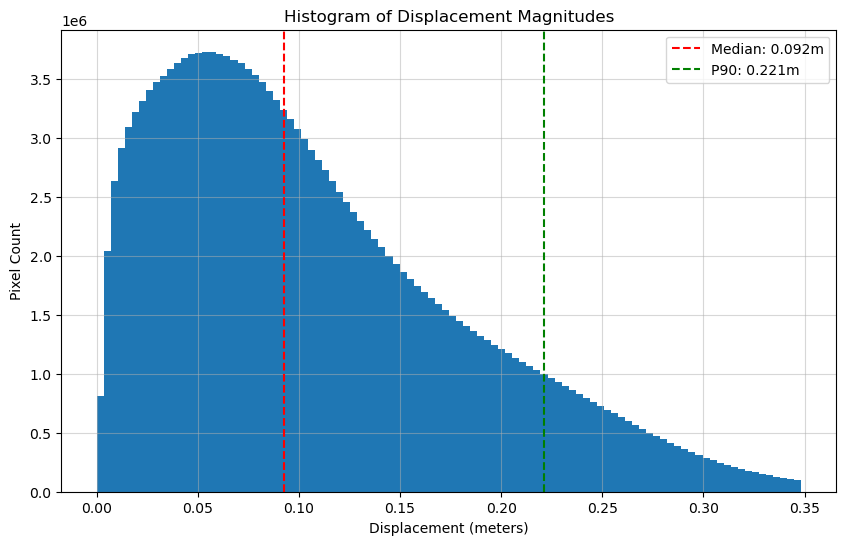

In [ ]:
import sys
import numpy as np
import rasterio
import laspy
from pathlib import Path
from scipy.ndimage import map_coordinates
import time
from tqdm import tqdm
import matplotlib.pyplot as plt

# --- CONFIGURATION ---

# Add the path to your gefolki python scripts if not in a standard location
GEFOLKI_PYTHON_PATH = '/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python'
if GEFOLKI_PYTHON_PATH not in sys.path:
    sys.path.append(GEFOLKI_PYTHON_PATH)

# --- KEY PARAMETER: Control the direction of the correction ---
# Use 1 to apply the flow as-is (e.g., X_new = X_old + dX).
# Use -1 to invert the flow (e.g., X_new = X_old - dX).
# This is useful if visual checks show the correction is being applied backwards.
CORRECTION_DIRECTION = 1

# --- INPUT FILE PATHS ---
# The original, full-density LAS/LAZ file to be corrected
LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las")

# The raster grid that defines the coordinate system for the flow fields.
# This MUST have the exact same dimensions as the flow field arrays.
REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg_simple.tif")

# The displacement fields calculated by gefolki
FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03.npy")
FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03.npy")

# --- OUTPUT FILE PATH ---
# Where the new, coregistered LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + "_coreg.las")


def apply_flow_to_las(las_in_path, las_out_path, grid_path, flow_u, flow_v, direction=1):
    """Applies a dense optical flow displacement field to a sparse LAS point cloud."""
    print(f"--- Applying Optical Flow Displacement (Direction: {direction}) ---")
    start_time = time.time()

    # 1. Get the coordinate transformation "dictionary" from the reference raster grid.
    with rasterio.open(grid_path) as src:
        transform = src.transform  # Translates from Pixel -> World (meters)
        H, W = src.height, src.width
        inv = ~transform           # The inverse: translates from World (meters) -> Pixel

    # Sanity check: ensure flow field dimensions match the reference grid
    if flow_u.shape != (H, W) or flow_v.shape != (H, W):
        raise ValueError(f"Flow shape {flow_u.shape} does not match raster size {(H, W)}")

    total_in, total_written = 0, 0

    # 2. Stream the input LAS file in chunks to manage memory.
    with laspy.open(las_in_path) as reader:
        header = reader.header
        # Setup progress bar using total points
        pbar = tqdm(total=reader.header.point_count, desc="Processing Points", unit="pts")
        
        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(2_000_000):
                total_in += len(pts)

                # 3. Convert point world coordinates (meters) to pixel coordinates.
                col, row = inv * (pts.x, pts.y)

                # 4. Filter to keep only points that fall within the reference grid.
                valid_mask = (col >= 0) & (col < W - 1) & (row >= 0) & (row < H - 1)
                if not np.any(valid_mask):
                    pbar.update(len(pts))
                    continue

                valid_pts = pts[valid_mask]
                coords = np.vstack((row[valid_mask], col[valid_mask]))

                # 5. Interpolate the displacement values at each point's sub-pixel location.
                du_pix = map_coordinates(flow_u, coords, order=1, mode="nearest")
                dv_pix = map_coordinates(flow_v, coords, order=1, mode="nearest")

                # 6. Convert pixel displacements back to world displacements (meters).
                dx_world = du_pix * transform.a
                dy_world = dv_pix * transform.e

                # 7. Apply the displacement, respecting the user-defined direction.
                valid_pts.x += direction * dx_world
                valid_pts.y += direction * dy_world

                # 8. Write the modified points and update progress bar.
                writer.write_points(valid_pts)
                total_written += len(valid_pts)
                pbar.update(len(pts))
        pbar.close()

    end_time = time.time()
    print(f"\n✅ Processing complete in {end_time - start_time:.2f} seconds.")
    print(f"   Saved coregistered point cloud to: {las_out_path}")
    if total_in > 0:
        print(f"   Kept {total_written:,} / {total_in:,} points ({total_written/total_in:.1%})")


def analyze_flow_field(grid_path, flow_u, flow_v):
    """Calculates and prints summary statistics, and plots a histogram."""
    print("\n--- Analyzing Displacement Field Statistics ---")
    
    with rasterio.open(grid_path) as src:
        T = src.transform
        pixel_width, pixel_height = T.a, T.e

    dx_m = flow_u * pixel_width
    dy_m = flow_v * pixel_height
    magnitude_m = np.hypot(dx_m, dy_m)

    valid_mask = np.isfinite(magnitude_m) & (magnitude_m > 0.0001)
    mag_m_valid = magnitude_m[valid_mask]
    
    if len(mag_m_valid) == 0:
        print("No significant displacement values found.")
        return

    # --- Print Statistics ---
    print(f"Found {len(mag_m_valid):,} pixels with significant displacement.")
    median_mag = np.median(mag_m_valid)
    p90_mag = np.percentile(mag_m_valid, 90)
    print(f"Median displacement magnitude: {median_mag:.4f} m")
    print(f"90th percentile magnitude:   {p90_mag:.4f} m")

    # --- Plot Histogram ---
    plt.figure(figsize=(10, 6))
    plt.hist(mag_m_valid, bins=100, range=(0, np.percentile(mag_m_valid, 99.5)))
    plt.title("Histogram of Displacement Magnitudes")
    plt.xlabel("Displacement (meters)")
    plt.ylabel("Pixel Count")
    plt.grid(True, alpha=0.5)
    plt.axvline(median_mag, color='r', linestyle='--', label=f'Median: {median_mag:.3f}m')
    plt.axvline(p90_mag, color='g', linestyle='--', label=f'P90: {p90_mag:.3f}m')
    plt.legend()
    plt.show()


if __name__ == '__main__':
    # --- Pre-flight checks for all input files ---
    input_files = [LAS_INPUT_PATH, REFERENCE_GRID_PATH, FLOW_U_PATH, FLOW_V_PATH]
    for f in input_files:
        if not f.exists():
            print(f"FATAL ERROR: Input file not found at: {f}")
            sys.exit(1)

    print("All input files found. Loading flow fields...")
    u = np.load(FLOW_U_PATH)
    v = np.load(FLOW_V_PATH)
    print("Flow fields loaded successfully.")

    # --- Run the main functions ---
    apply_flow_to_las(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u,
        flow_v=v,
        direction=CORRECTION_DIRECTION
    )

    analyze_flow_field(
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u,
        flow_v=v
    )

In [ ]:
import sys
import numpy as np
import rasterio
import laspy
from pathlib import Path
from tqdm import tqdm
import time

# --- CONFIGURATION: INPUT FILE PATHS ---

# 1. The original, full-density LAS/LAZ file that needs to be shifted
LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las")

# 2. The displacement fields calculated by the previous gefolki script
FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03.npy")
FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03.npy")

# 3. The reference grid that MUST have the same dimensions as the flow fields.
#    This is used to convert the flow fields from pixels to meters.
REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg_simple.tif")

# --- CONFIGURATION: OUTPUT FILE PATH ---
# Where the new, globally translated LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + "_coreg.las")


def calculate_median_translation(flow_u_path: Path, flow_v_path: Path, grid_path: Path) -> tuple[float, float]:
    """
    Analyzes flow fields to calculate the median X and Y translation in meters.

    Args:
        flow_u_path (Path): Path to the U-component of the flow field (.npy).
        flow_v_path (Path): Path to the V-component of the flow field (.npy).
        grid_path (Path): Path to the reference raster that defines the flow grid.

    Returns:
        A tuple containing the median X and Y translation in meters (dx, dy).
    """
    print("--- Step 1/2: Calculating Median Translation from Flow Fields ---")
    
    # Load the flow fields
    flow_u = np.load(flow_u_path)
    flow_v = np.load(flow_v_path)

    # Open the reference grid to get the pixel-to-meter conversion factor
    with rasterio.open(grid_path) as src:
        T = src.transform
        pixel_width = T.a   # Pixel width in meters (typically > 0)
        pixel_height = T.e  # Pixel height in meters (typically < 0 for north-up)

    # Convert the entire flow field from pixel displacements to meter displacements
    dx_m = flow_u * pixel_width
    dy_m = flow_v * pixel_height

    # Create a mask to exclude invalid (e.g., NaN) and near-zero values for robust statistics
    magnitude_m = np.hypot(dx_m, dy_m)
    valid_mask = np.isfinite(magnitude_m) & (magnitude_m > 0.0001) # Filter shifts < 0.1mm
    
    if not np.any(valid_mask):
        print("Warning: No significant displacement values found in flow fields.")
        return 0.0, 0.0

    # Calculate the median of the valid displacement values
    median_x = np.median(dx_m[valid_mask])
    median_y = np.median(dy_m[valid_mask])
    
    print(f"Calculation complete.")
    return median_x, median_y


def apply_global_translation(las_in_path: Path, las_out_path: Path, dx: float, dy: float):
    """
    Applies a constant X, Y translation to all points in a LAS file.
    """
    print("\n--- Step 2/2: Applying Global Translation to Point Cloud ---")
    print(f"Input file:  {las_in_path.name}")
    print(f"Output file: {las_out_path.name}")
    print(f"Applying Translation (dx, dy): ({dx:+.4f} m, {dy:+.4f} m)")

    with laspy.open(las_in_path) as reader:
        header = reader.header
        pbar = tqdm(total=header.point_count, desc="Translating Points", unit="pts")

        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(2_000_000):
                # Apply the constant shift to the X and Y coordinates
                pts.x += dx
                pts.y += dy
                # Z coordinate is unchanged
                
                writer.write_points(pts)
                pbar.update(len(pts))
        pbar.close()

    print("\n✅ Translation complete.")


if __name__ == '__main__':
    # --- Pre-flight check for all necessary input files ---
    input_files = [LAS_INPUT_PATH, FLOW_U_PATH, FLOW_V_PATH, REFERENCE_GRID_PATH]
    all_files_found = True
    for f in input_files:
        if not f.exists():
            print(f"FATAL ERROR: Input file not found at: {f}")
            all_files_found = False
    
    if not all_files_found:
        sys.exit(1)
        
    print("All input files found. Starting process...")

    # --- Run the automated workflow ---
    # Step 1: Calculate the median shift
    dx_median, dy_median = calculate_median_translation(
        flow_u_path=FLOW_U_PATH,
        flow_v_path=FLOW_V_PATH,
        grid_path=REFERENCE_GRID_PATH
    )

    # Step 2: Apply the calculated shift to the LAS file
    apply_global_translation(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        dx=dx_median,
        dy=dy_median
    )

All input files found. Starting process...
--- Step 1/2: Calculating Median Translation from Flow Fields ---
Calculation complete.

--- Step 2/2: Applying Global Translation to Point Cloud ---
Input file:  20220519_SASMDD0001_triple_AusGeoid.las
Output file: 20220519_SASMDD0001_triple_AusGeoid_coreg.las
Applying Translation (dx, dy): (+0.0012 m, -0.0069 m)


Translating Points: 100%|██████████| 285786198/285786198 [04:22<00:00, 1088648.15pts/s]


✅ Translation complete.


In [ ]:
##test 2
import sys
import numpy as np
import rasterio
import laspy
from pathlib import Path
from scipy.ndimage import map_coordinates
import time
from tqdm import tqdm
import matplotlib.pyplot as plt

# --- CONFIGURATION ---

# Add the path to your gefolki python scripts if not in a standard location
GEFOLKI_PYTHON_PATH = '/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python'
if GEFOLKI_PYTHON_PATH not in sys.path:
    sys.path.append(GEFOLKI_PYTHON_PATH)

# --- KEY PARAMETER: Control the direction of the correction ---
# Use 1 to apply the flow as-is.
# Use -1 to invert the flow if visual checks show the correction is backwards.
CORRECTION_DIRECTION = 1

# --- INPUT FILE PATHS ---
# The original, full-density LAS/LAZ file to be corrected
LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las")

# The raster grid that defines the coordinate system for the flow fields.
# This MUST have the exact same dimensions as the flow field arrays.
REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg_simple.tif")

# The displacement fields calculated by gefolki
FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03.npy")
FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03.npy")

# --- OUTPUT FILE PATH ---
# Where the new, fully coregistered LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + "_coreg.las")


def apply_full_flow_to_las(las_in_path, las_out_path, grid_path, flow_u, flow_v, direction=1):
    """Applies the full, dense optical flow displacement field to a LAS point cloud."""
    print(f"--- Applying Full Non-Linear Correction (Direction: {direction}) ---")
    start_time = time.time()

    with rasterio.open(grid_path) as src:
        transform = src.transform
        H, W = src.height, src.width
        inv = ~transform

    if flow_u.shape != (H, W) or flow_v.shape != (H, W):
        raise ValueError(f"Flow shape {flow_u.shape} does not match raster size {(H, W)}")

    with laspy.open(las_in_path) as reader:
        header = reader.header
        pbar = tqdm(total=header.point_count, desc="Applying Full Flow", unit="pts")
        
        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(2_000_000):
                col, row = inv * (pts.x, pts.y)
                valid_mask = (col >= 0) & (col < W - 1) & (row >= 0) & (row < H - 1)
                
                if not np.any(valid_mask):
                    pbar.update(len(pts))
                    continue

                valid_pts = pts[valid_mask]
                coords = np.vstack((row[valid_mask], col[valid_mask]))

                du_pix = map_coordinates(flow_u, coords, order=1, mode="nearest")
                dv_pix = map_coordinates(flow_v, coords, order=1, mode="nearest")

                dx_world = du_pix * transform.a
                dy_world = dv_pix * transform.e

                valid_pts.x += direction * dx_world
                valid_pts.y += direction * dy_world

                writer.write_points(valid_pts)
                pbar.update(len(pts))
        pbar.close()

    end_time = time.time()
    print(f"\n✅ Full coregistration complete in {end_time - start_time:.2f} seconds.")
    print(f"   Saved final point cloud to: {las_out_path}")


if __name__ == '__main__':
    input_files = [LAS_INPUT_PATH, REFERENCE_GRID_PATH, FLOW_U_PATH, FLOW_V_PATH]
    for f in input_files:
        if not f.exists():
            print(f"FATAL ERROR: Input file not found at: {f}")
            sys.exit(1)

    print("All input files found. Loading flow fields...")
    u = np.load(FLOW_U_PATH)
    v = np.load(FLOW_V_PATH)
    print("Flow fields loaded successfully.")

    apply_full_flow_to_las(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u,
        flow_v=v,
        direction=CORRECTION_DIRECTION
    )

All input files found. Loading flow fields...
Flow fields loaded successfully.
--- Applying Full Non-Linear Correction (Direction: 1) ---


Applying Full Flow: 100%|██████████| 285786198/285786198 [03:43<00:00, 1278245.62pts/s]


✅ Full coregistration complete in 223.59 seconds.
   Saved final point cloud to: /media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las


In [ ]:
##test 2
import sys
import numpy as np
import rasterio
import laspy
from pathlib import Path
from scipy.ndimage import map_coordinates
import time
from tqdm import tqdm

# --- CONFIGURATION ---

# Add the path to your gefolki python scripts if not in a standard location
GEFOLKI_PYTHON_PATH = '/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python'
if GEFOLKI_PYTHON_PATH not in sys.path:
    sys.path.append(GEFOLKI_PYTHON_PATH)

# --- KEY PARAMETER: Control the direction of the correction ---
# Use 1 to apply the flow as-is (e.g., X_new = X_old + dX).
# Use -1 to invert the flow if visual checks show the correction is backwards.
CORRECTION_DIRECTION = 1

# --- INPUT FILE PATHS ---
# The original, full-density LAS/LAZ file to be corrected
LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las")

# The raster grid that defines the coordinate system for the flow fields.
# This MUST have the exact same dimensions as the flow field arrays.
REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg_simple.tif")

# The displacement fields calculated by gefolki
FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03.npy")
FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03.npy")

# --- OUTPUT FILE PATH ---
# Where the new, fully coregistered LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + "_coreg.las")


def apply_full_flow_to_las(las_in_path, las_out_path, grid_path, flow_u, flow_v, direction=1):
    """Applies the full, dense optical flow displacement field to a LAS point cloud."""
    print(f"--- Applying Full Non-Linear Correction (Direction: {direction}) ---")
    start_time = time.time()

    # 1. Get the coordinate transformation "dictionary" from the reference raster.
    # This allows us to translate between World coordinates (meters) and Pixel coordinates.
    with rasterio.open(grid_path) as src:
        transform = src.transform  # Translates from Pixel -> World (meters)
        H, W = src.height, src.width
        inv = ~transform           # The inverse: translates from World (meters) -> Pixel

    # Sanity check to ensure our map (flow field) and globe (reference grid) match
    if flow_u.shape != (H, W) or flow_v.shape != (H, W):
        raise ValueError(f"Flow shape {flow_u.shape} does not match raster size {(H, W)}")

    # 2. Open the input and output LAS files, streaming the data in chunks.
    with laspy.open(las_in_path) as reader:
        header = reader.header
        pbar = tqdm(total=header.point_count, desc="Applying Full Flow", unit="pts")
        
        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(2_000_000): # Process 2 million points at a time
                
                # 3. For each point, find its address (row, col) on the flow field grid.
                col, row = inv * (pts.x, pts.y)
                
                # 4. Keep only the points that actually fall within the correction grid.
                valid_mask = (col >= 0) & (col < W - 1) & (row >= 0) & (row < H - 1)
                if not np.any(valid_mask):
                    pbar.update(len(pts))
                    continue # Skip this chunk if no points overlap

                valid_pts = pts[valid_mask]
                coords = np.vstack((row[valid_mask], col[valid_mask]))

                # 5. Look up the precise correction (in pixels) for each point's address.
                #    `map_coordinates` interpolates the value for sub-pixel locations.
                du_pix = map_coordinates(flow_u, coords, order=1, mode="nearest")
                dv_pix = map_coordinates(flow_v, coords, order=1, mode="nearest")

                # 6. Translate the correction from pixels back to meters.
                dx_world = du_pix * transform.a  # transform.a = pixel width in meters
                dy_world = dv_pix * transform.e  # transform.e = pixel height in meters

                # 7. Apply the final, specific correction to each point.
                valid_pts.x += direction * dx_world
                valid_pts.y += direction * dy_world

                # 8. Write the corrected points to the new file.
                writer.write_points(valid_pts)
                pbar.update(len(pts))
        pbar.close()

    end_time = time.time()
    print(f"\n✅ Full coregistration complete in {end_time - start_time:.2f} seconds.")
    print(f"   Saved final point cloud to: {las_out_path}")


if __name__ == '__main__':
    # --- Pre-flight check for all necessary input files ---
    input_files = [LAS_INPUT_PATH, REFERENCE_GRID_PATH, FLOW_U_PATH, FLOW_V_PATH]
    for f in input_files:
        if not f.exists():
            print(f"FATAL ERROR: Input file not found at: {f}")
            sys.exit(1)

    print("All input files found. Loading flow fields...")
    u = np.load(FLOW_U_PATH)
    v = np.load(FLOW_V_PATH)
    print("Flow fields loaded successfully.")

    # --- Run the main function ---
    apply_full_flow_to_las(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u,
        flow_v=v,
        direction=CORRECTION_DIRECTION
    )

All input files found. Loading flow fields...
Flow fields loaded successfully.
--- Applying Full Non-Linear Correction (Direction: 1) ---


Applying Full Flow: 100%|██████████| 285786198/285786198 [03:04<00:00, 1549032.20pts/s]


✅ Full coregistration complete in 184.50 seconds.
   Saved final point cloud to: /media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las


In [ ]:
##test 2
import sys
import numpy as np
import rasterio
import laspy
from pathlib import Path
from scipy.ndimage import map_coordinates
import time
from tqdm import tqdm

# --- CONFIGURATION ---

# Add the path to your gefolki python scripts if not in a standard location
GEFOLKI_PYTHON_PATH = '/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python'
if GEFOLKI_PYTHON_PATH not in sys.path:
    sys.path.append(GEFOLKI_PYTHON_PATH)

# --- KEY PARAMETER: Control the direction of the correction ---
# Use 1 to apply the flow as-is (e.g., X_new = X_old + dX).
# Use -1 to invert the flow if visual checks show the correction is backwards.
CORRECTION_DIRECTION = -1

# --- INPUT FILE PATHS ---
# The original, full-density LAS/LAZ file to be corrected
LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las")

# The raster grid that defines the coordinate system for the flow fields.
# This MUST have the exact same dimensions as the flow field arrays.
REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg_simple.tif")

# The displacement fields calculated by gefolki
FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03.npy")
FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03.npy")

# --- OUTPUT FILE PATH ---
# Where the new, fully coregistered LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + "_coreg.las")


def apply_full_flow_to_las(las_in_path, las_out_path, grid_path, flow_u, flow_v, direction=1):
    """Applies the full, dense optical flow displacement field to a LAS point cloud."""
    print(f"--- Applying Full Non-Linear Correction (Direction: {direction}) ---")
    start_time = time.time()

    # 1. Get the coordinate transformation "dictionary" from the reference raster.
    # This allows us to translate between World coordinates (meters) and Pixel coordinates.
    with rasterio.open(grid_path) as src:
        transform = src.transform  # Translates from Pixel -> World (meters)
        H, W = src.height, src.width
        inv = ~transform           # The inverse: translates from World (meters) -> Pixel

    # Sanity check to ensure our map (flow field) and globe (reference grid) match
    if flow_u.shape != (H, W) or flow_v.shape != (H, W):
        raise ValueError(f"Flow shape {flow_u.shape} does not match raster size {(H, W)}")

    # 2. Open the input and output LAS files, streaming the data in chunks.
    with laspy.open(las_in_path) as reader:
        header = reader.header
        pbar = tqdm(total=header.point_count, desc="Applying Full Flow", unit="pts")
        
        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(2_000_000): # Process 2 million points at a time
                
                # 3. For each point, find its address (row, col) on the flow field grid.
                col, row = inv * (pts.x, pts.y)
                
                # 4. Keep only the points that actually fall within the correction grid.
                valid_mask = (col >= 0) & (col < W - 1) & (row >= 0) & (row < H - 1)
                if not np.any(valid_mask):
                    pbar.update(len(pts))
                    continue # Skip this chunk if no points overlap

                valid_pts = pts[valid_mask]
                coords = np.vstack((row[valid_mask], col[valid_mask]))

                # 5. Look up the precise correction (in pixels) for each point's address.
                #    `map_coordinates` interpolates the value for sub-pixel locations.
                du_pix = map_coordinates(flow_u, coords, order=1, mode="nearest")
                dv_pix = map_coordinates(flow_v, coords, order=1, mode="nearest")

                # 6. Translate the correction from pixels back to meters.
                dx_world = du_pix * transform.a  # transform.a = pixel width in meters
                dy_world = dv_pix * transform.e  # transform.e = pixel height in meters

                # 7. Apply the final, specific correction to each point.
                valid_pts.x += direction * dx_world
                valid_pts.y += direction * dy_world

                # 8. Write the corrected points to the new file.
                writer.write_points(valid_pts)
                pbar.update(len(pts))
        pbar.close()

    end_time = time.time()
    print(f"\n✅ Full coregistration complete in {end_time - start_time:.2f} seconds.")
    print(f"   Saved final point cloud to: {las_out_path}")


if __name__ == '__main__':
    # --- Pre-flight check for all necessary input files ---
    input_files = [LAS_INPUT_PATH, REFERENCE_GRID_PATH, FLOW_U_PATH, FLOW_V_PATH]
    for f in input_files:
        if not f.exists():
            print(f"FATAL ERROR: Input file not found at: {f}")
            sys.exit(1)

    print("All input files found. Loading flow fields...")
    u = np.load(FLOW_U_PATH)
    v = np.load(FLOW_V_PATH)
    print("Flow fields loaded successfully.")

    # --- Run the main function ---
    apply_full_flow_to_las(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u,
        flow_v=v,
        direction=CORRECTION_DIRECTION
    )

All input files found. Loading flow fields...
Flow fields loaded successfully.
--- Applying Full Non-Linear Correction (Direction: -1) ---


Applying Full Flow: 100%|██████████| 285786198/285786198 [01:12<00:00, 3936650.70pts/s]


✅ Full coregistration complete in 72.60 seconds.
   Saved final point cloud to: /media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las


Connected to fvc_structure (Python 3.10.18)

In [ ]:
##test 2
import sys
import numpy as np
import rasterio
import laspy
from pathlib import Path
from scipy.ndimage import map_coordinates
import time
from tqdm import tqdm

# --- CONFIGURATION ---

# Add the path to your gefolki python scripts if not in a standard location
GEFOLKI_PYTHON_PATH = '/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python'
if GEFOLKI_PYTHON_PATH not in sys.path:
    sys.path.append(GEFOLKI_PYTHON_PATH)

# --- KEY PARAMETER: Control the direction of the correction ---
# Use 1 to apply the flow as-is (e.g., X_new = X_old + dX).
# Use -1 to invert the flow if visual checks show the correction is backwards.
CORRECTION_DIRECTION = -1

# --- INPUT FILE PATHS ---
# The original, full-density LAS/LAZ file to be corrected
# LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las")
LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/cloud2d765c57b8471e2c.las")

# The raster grid that defines the coordinate system for the flow fields.
# This MUST have the exact same dimensions as the flow field arrays.
# REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg.tif")
REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif")

# The displacement fields calculated by gefolki
# FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03.npy")
# FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03.npy")

FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03_l2.npy")
FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03_l2.npy")

# --- OUTPUT FILE PATH ---
# Where the new, fully coregistered LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + "_coreg.las")


def apply_full_flow_to_las(las_in_path, las_out_path, grid_path, flow_u, flow_v, direction=1):
    """Applies the full, dense optical flow displacement field to a LAS point cloud."""
    print(f"--- Applying Full Non-Linear Correction (Direction: {direction}) ---")
    start_time = time.time()

    # 1. Get the coordinate transformation "dictionary" from the reference raster.
    # This allows us to translate between World coordinates (meters) and Pixel coordinates.
    with rasterio.open(grid_path) as src:
        transform = src.transform  # Translates from Pixel -> World (meters)
        H, W = src.height, src.width
        inv = ~transform           # The inverse: translates from World (meters) -> Pixel

    # Sanity check to ensure our map (flow field) and globe (reference grid) match
    if flow_u.shape != (H, W) or flow_v.shape != (H, W):
        raise ValueError(f"Flow shape {flow_u.shape} does not match raster size {(H, W)}")

    # 2. Open the input and output LAS files, streaming the data in chunks.
    with laspy.open(las_in_path) as reader:
        header = reader.header
        pbar = tqdm(total=header.point_count, desc="Applying Full Flow", unit="pts")
        
        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(2_000_000): # Process 2 million points at a time
                
                # 3. For each point, find its address (row, col) on the flow field grid.
                col, row = inv * (pts.x, pts.y)
                
                # 4. Keep only the points that actually fall within the correction grid.
                valid_mask = (col >= 0) & (col < W - 1) & (row >= 0) & (row < H - 1)
                if not np.any(valid_mask):
                    pbar.update(len(pts))
                    continue # Skip this chunk if no points overlap

                valid_pts = pts[valid_mask]
                coords = np.vstack((row[valid_mask], col[valid_mask]))

                # 5. Look up the precise correction (in pixels) for each point's address.
                #    `map_coordinates` interpolates the value for sub-pixel locations.
                du_pix = map_coordinates(flow_u, coords, order=1, mode="nearest")
                dv_pix = map_coordinates(flow_v, coords, order=1, mode="nearest")

                # 6. Translate the correction from pixels back to meters.
                dx_world = du_pix * transform.a  # transform.a = pixel width in meters
                dy_world = dv_pix * transform.e  # transform.e = pixel height in meters

                # 7. Apply the final, specific correction to each point.
                valid_pts.x += direction * dx_world
                valid_pts.y += direction * dy_world

                # 8. Write the corrected points to the new file.
                writer.write_points(valid_pts)
                pbar.update(len(pts))
        pbar.close()

    end_time = time.time()
    print(f"\n✅ Full coregistration complete in {end_time - start_time:.2f} seconds.")
    print(f"   Saved final point cloud to: {las_out_path}")


if __name__ == '__main__':
    # --- Pre-flight check for all necessary input files ---
    input_files = [LAS_INPUT_PATH, REFERENCE_GRID_PATH, FLOW_U_PATH, FLOW_V_PATH]
    for f in input_files:
        if not f.exists():
            print(f"FATAL ERROR: Input file not found at: {f}")
            sys.exit(1)

    print("All input files found. Loading flow fields...")
    u = np.load(FLOW_U_PATH)
    v = np.load(FLOW_V_PATH)
    print("Flow fields loaded successfully.")

    # --- Run the main function ---
    apply_full_flow_to_las(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u,
        flow_v=v,
        direction=CORRECTION_DIRECTION
    )

All input files found. Loading flow fields...
Flow fields loaded successfully.
--- Applying Full Non-Linear Correction (Direction: -1) ---


Applying Full Flow: 100%|██████████| 181506517/181506517 [00:39<00:00, 4600802.64pts/s]


✅ Full coregistration complete in 39.46 seconds.
   Saved final point cloud to: /media/laura/laura_usb/uas_data/DD0001/lidar_l2/cloud2d765c57b8471e2c_coreg.las


Connected to fvc_structure (Python 3.10.18)

In [ ]:
##test 2
import sys
import numpy as np
import rasterio
import laspy
from pathlib import Path
from scipy.ndimage import map_coordinates
import time
from tqdm import tqdm

# --- CONFIGURATION ---

# Add the path to your gefolki python scripts if not in a standard location
GEFOLKI_PYTHON_PATH = '/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python'
if GEFOLKI_PYTHON_PATH not in sys.path:
    sys.path.append(GEFOLKI_PYTHON_PATH)

# --- KEY PARAMETER: Control the direction of the correction ---
# Use 1 to apply the flow as-is (e.g., X_new = X_old + dX).
# Use -1 to invert the flow if visual checks show the correction is backwards.
CORRECTION_DIRECTION = -1

# --- INPUT FILE PATHS ---
# The original, full-density LAS/LAZ file to be corrected
# LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las")
LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/cloud2d765c57b8471e2c.las")

# The raster grid that defines the coordinate system for the flow fields.
# This MUST have the exact same dimensions as the flow field arrays.
# REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg.tif")
REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif")

# The displacement fields calculated by gefolki
# FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03.npy")
# FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03.npy")

FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03_l2.npy")
FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03_l2.npy")

# --- OUTPUT FILE PATH ---
# Where the new, fully coregistered LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + "_coreg.las")


def apply_full_flow_to_las(las_in_path, las_out_path, grid_path, flow_u, flow_v, direction=1):
    """Applies the full, dense optical flow displacement field to a LAS point cloud."""
    print(f"--- Applying Full Non-Linear Correction (Direction: {direction}) ---")
    start_time = time.time()

    # 1. Get the coordinate transformation "dictionary" from the reference raster.
    # This allows us to translate between World coordinates (meters) and Pixel coordinates.
    with rasterio.open(grid_path) as src:
        transform = src.transform  # Translates from Pixel -> World (meters)
        H, W = src.height, src.width
        inv = ~transform           # The inverse: translates from World (meters) -> Pixel

    # Sanity check to ensure our map (flow field) and globe (reference grid) match
    if flow_u.shape != (H, W) or flow_v.shape != (H, W):
        raise ValueError(f"Flow shape {flow_u.shape} does not match raster size {(H, W)}")

    # 2. Open the input and output LAS files, streaming the data in chunks.
    with laspy.open(las_in_path) as reader:
        header = reader.header
        pbar = tqdm(total=header.point_count, desc="Applying Full Flow", unit="pts")
        
        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(2_000_000): # Process 2 million points at a time
                
                # 3. For each point, find its address (row, col) on the flow field grid.
                col, row = inv * (pts.x, pts.y)
                
                # 4. Keep only the points that actually fall within the correction grid.
                valid_mask = (col >= 0) & (col < W - 1) & (row >= 0) & (row < H - 1)
                if not np.any(valid_mask):
                    pbar.update(len(pts))
                    continue # Skip this chunk if no points overlap

                valid_pts = pts[valid_mask]
                coords = np.vstack((row[valid_mask], col[valid_mask]))

                # 5. Look up the precise correction (in pixels) for each point's address.
                #    `map_coordinates` interpolates the value for sub-pixel locations.
                du_pix = map_coordinates(flow_u, coords, order=1, mode="nearest")
                dv_pix = map_coordinates(flow_v, coords, order=1, mode="nearest")

                # 6. Translate the correction from pixels back to meters.
                dx_world = du_pix * transform.a  # transform.a = pixel width in meters
                dy_world = dv_pix * transform.e  # transform.e = pixel height in meters

                # 7. Apply the final, specific correction to each point.
                valid_pts.x += direction * dx_world
                valid_pts.y += direction * dy_world

                # 8. Write the corrected points to the new file.
                writer.write_points(valid_pts)
                pbar.update(len(pts))
        pbar.close()

    end_time = time.time()
    print(f"\n✅ Full coregistration complete in {end_time - start_time:.2f} seconds.")
    print(f"   Saved final point cloud to: {las_out_path}")


if __name__ == '__main__':
    # --- Pre-flight check for all necessary input files ---
    input_files = [LAS_INPUT_PATH, REFERENCE_GRID_PATH, FLOW_U_PATH, FLOW_V_PATH]
    for f in input_files:
        if not f.exists():
            print(f"FATAL ERROR: Input file not found at: {f}")
            sys.exit(1)

    print("All input files found. Loading flow fields...")
    u = np.load(FLOW_U_PATH)
    v = np.load(FLOW_V_PATH)
    print("Flow fields loaded successfully.")

    # --- Run the main function ---
    apply_full_flow_to_las(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u,
        flow_v=v,
        direction=CORRECTION_DIRECTION
    )

All input files found. Loading flow fields...
Flow fields loaded successfully.
--- Applying Full Non-Linear Correction (Direction: -1) ---


Applying Full Flow: 100%|██████████| 181506517/181506517 [00:37<00:00, 4780524.16pts/s]


✅ Full coregistration complete in 37.98 seconds.
   Saved final point cloud to: /media/laura/laura_usb/uas_data/DD0001/lidar_l2/cloud2d765c57b8471e2c_coreg.las


In [ ]:
##test 2
import sys
import numpy as np
import rasterio
import laspy
from pathlib import Path
from scipy.ndimage import map_coordinates
import time
from tqdm import tqdm

# --- CONFIGURATION ---

# Add the path to your gefolki python scripts if not in a standard location
GEFOLKI_PYTHON_PATH = '/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python'
if GEFOLKI_PYTHON_PATH not in sys.path:
    sys.path.append(GEFOLKI_PYTHON_PATH)

# --- KEY PARAMETER: Control the direction of the correction ---
# Use 1 to apply the flow as-is (e.g., X_new = X_old + dX).
# Use -1 to invert the flow if visual checks show the correction is backwards.
CORRECTION_DIRECTION = -1

# --- INPUT FILE PATHS ---
# The original, full-density LAS/LAZ file to be corrected
# LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las")
LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/cloud2d765c57b8471e2c.las")

# The raster grid that defines the coordinate system for the flow fields.
# This MUST have the exact same dimensions as the flow field arrays.
# REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg.tif")
REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif")

# The displacement fields calculated by gefolki
# FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03.npy")
# FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03.npy")

FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03_l2.npy")
FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03_l2.npy")

# --- OUTPUT FILE PATH ---
# Where the new, fully coregistered LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + "_coreg_bilin2.las")


def apply_full_flow_to_las(las_in_path, las_out_path, grid_path, flow_u, flow_v, direction=1):
    """Applies the full, dense optical flow displacement field to a LAS point cloud."""
    print(f"--- Applying Full Non-Linear Correction (Direction: {direction}) ---")
    start_time = time.time()

    # 1. Get the coordinate transformation "dictionary" from the reference raster.
    # This allows us to translate between World coordinates (meters) and Pixel coordinates.
    with rasterio.open(grid_path) as src:
        transform = src.transform  # Translates from Pixel -> World (meters)
        H, W = src.height, src.width
        inv = ~transform           # The inverse: translates from World (meters) -> Pixel

    # Sanity check to ensure our map (flow field) and globe (reference grid) match
    if flow_u.shape != (H, W) or flow_v.shape != (H, W):
        raise ValueError(f"Flow shape {flow_u.shape} does not match raster size {(H, W)}")

    # 2. Open the input and output LAS files, streaming the data in chunks.
    with laspy.open(las_in_path) as reader:
        header = reader.header
        pbar = tqdm(total=header.point_count, desc="Applying Full Flow", unit="pts")
        
        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(2_000_000): # Process 2 million points at a time
                
                # 3. For each point, find its address (row, col) on the flow field grid.
                col, row = inv * (pts.x, pts.y)
                
                # 4. Keep only the points that actually fall within the correction grid.
                valid_mask = (col >= 0) & (col < W - 1) & (row >= 0) & (row < H - 1)
                if not np.any(valid_mask):
                    pbar.update(len(pts))
                    continue # Skip this chunk if no points overlap

                valid_pts = pts[valid_mask]
                coords = np.vstack((row[valid_mask], col[valid_mask]))

                # 5. Look up the precise correction (in pixels) for each point's address.
                #    `map_coordinates` interpolates the value for sub-pixel locations.
                du_pix = map_coordinates(flow_u, coords, order=2, mode="nearest")
                dv_pix = map_coordinates(flow_v, coords, order=2, mode="nearest")

                # 6. Translate the correction from pixels back to meters.
                dx_world = du_pix * transform.a  # transform.a = pixel width in meters
                dy_world = dv_pix * transform.e  # transform.e = pixel height in meters

                # 7. Apply the final, specific correction to each point.
                valid_pts.x += direction * dx_world
                valid_pts.y += direction * dy_world

                # 8. Write the corrected points to the new file.
                writer.write_points(valid_pts)
                pbar.update(len(pts))
        pbar.close()

    end_time = time.time()
    print(f"\n✅ Full coregistration complete in {end_time - start_time:.2f} seconds.")
    print(f"   Saved final point cloud to: {las_out_path}")


if __name__ == '__main__':
    # --- Pre-flight check for all necessary input files ---
    input_files = [LAS_INPUT_PATH, REFERENCE_GRID_PATH, FLOW_U_PATH, FLOW_V_PATH]
    for f in input_files:
        if not f.exists():
            print(f"FATAL ERROR: Input file not found at: {f}")
            sys.exit(1)

    print("All input files found. Loading flow fields...")
    u = np.load(FLOW_U_PATH)
    v = np.load(FLOW_V_PATH)
    print("Flow fields loaded successfully.")

    # --- Run the main function ---
    apply_full_flow_to_las(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u,
        flow_v=v,
        direction=CORRECTION_DIRECTION
    )

All input files found. Loading flow fields...
Flow fields loaded successfully.
--- Applying Full Non-Linear Correction (Direction: -1) ---


Applying Full Flow: 100%|██████████| 181506517/181506517 [13:56<00:00, 216931.79pts/s]


✅ Full coregistration complete in 836.70 seconds.
   Saved final point cloud to: /media/laura/laura_usb/uas_data/DD0001/lidar_l2/cloud2d765c57b8471e2c_coreg_bilin2.las


In [ ]:
##test 2
import sys
import numpy as np
import rasterio
import laspy
from pathlib import Path
from scipy.ndimage import map_coordinates
import time
from tqdm import tqdm

# --- CONFIGURATION ---

# Add the path to your gefolki python scripts if not in a standard location
GEFOLKI_PYTHON_PATH = '/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python'
if GEFOLKI_PYTHON_PATH not in sys.path:
    sys.path.append(GEFOLKI_PYTHON_PATH)

# --- KEY PARAMETER: Control the direction of the correction ---
# Use 1 to apply the flow as-is (e.g., X_new = X_old + dX).
# Use -1 to invert the flow if visual checks show the correction is backwards.
CORRECTION_DIRECTION = -1

# --- INPUT FILE PATHS ---
# The original, full-density LAS/LAZ file to be corrected
# LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las")
LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/cloud2d765c57b8471e2c.las")

# The raster grid that defines the coordinate system for the flow fields.
# This MUST have the exact same dimensions as the flow field arrays.
# REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg.tif")
REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif")

# The displacement fields calculated by gefolki
# FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03.npy")
# FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03.npy")

FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03_l2.npy")
FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03_l2.npy")

# --- OUTPUT FILE PATH ---
# Where the new, fully coregistered LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + "_coreg_bilin2.las")


def apply_full_flow_to_las(las_in_path, las_out_path, grid_path, flow_u, flow_v, direction=1):
    """Applies the full, dense optical flow displacement field to a LAS point cloud."""
    print(f"--- Applying Full Non-Linear Correction (Direction: {direction}) ---")
    start_time = time.time()

    # 1. Get the coordinate transformation "dictionary" from the reference raster.
    # This allows us to translate between World coordinates (meters) and Pixel coordinates.
    with rasterio.open(grid_path) as src:
        transform = src.transform  # Translates from Pixel -> World (meters)
        H, W = src.height, src.width
        inv = ~transform           # The inverse: translates from World (meters) -> Pixel

    # Sanity check to ensure our map (flow field) and globe (reference grid) match
    if flow_u.shape != (H, W) or flow_v.shape != (H, W):
        raise ValueError(f"Flow shape {flow_u.shape} does not match raster size {(H, W)}")

    # 2. Open the input and output LAS files, streaming the data in chunks.
    with laspy.open(las_in_path) as reader:
        header = reader.header
        pbar = tqdm(total=header.point_count, desc="Applying Full Flow", unit="pts")
        
        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(2_000_000): # Process 2 million points at a time
                
                # 3. For each point, find its address (row, col) on the flow field grid.
                col, row = inv * (pts.x, pts.y)
                
                # 4. Keep only the points that actually fall within the correction grid.
                valid_mask = (col >= 0) & (col < W - 1) & (row >= 0) & (row < H - 1)
                if not np.any(valid_mask):
                    pbar.update(len(pts))
                    continue # Skip this chunk if no points overlap

                valid_pts = pts[valid_mask]
                coords = np.vstack((row[valid_mask], col[valid_mask]))

                # 5. Look up the precise correction (in pixels) for each point's address.
                #    `map_coordinates` interpolates the value for sub-pixel locations.
                # du_pix = map_coordinates(flow_u, coords, order=2, mode="nearest")
                # dv_pix = map_coordinates(flow_v, coords, order=2, mode="nearest")
                du_pix = map_coordinates(flow_u, coords, order=2, mode="reflect")
                dv_pix = map_coordinates(flow_v, coords, order=2, mode="reflect")

                # 6. Translate the correction from pixels back to meters.
                dx_world = du_pix * transform.a  # transform.a = pixel width in meters
                dy_world = dv_pix * transform.e  # transform.e = pixel height in meters

                # 7. Apply the final, specific correction to each point.
                valid_pts.x += direction * dx_world
                valid_pts.y += direction * dy_world

                # 8. Write the corrected points to the new file.
                writer.write_points(valid_pts)
                pbar.update(len(pts))
        pbar.close()

    end_time = time.time()
    print(f"\n✅ Full coregistration complete in {end_time - start_time:.2f} seconds.")
    print(f"   Saved final point cloud to: {las_out_path}")


if __name__ == '__main__':
    # --- Pre-flight check for all necessary input files ---
    input_files = [LAS_INPUT_PATH, REFERENCE_GRID_PATH, FLOW_U_PATH, FLOW_V_PATH]
    for f in input_files:
        if not f.exists():
            print(f"FATAL ERROR: Input file not found at: {f}")
            sys.exit(1)

    print("All input files found. Loading flow fields...")
    u = np.load(FLOW_U_PATH)
    v = np.load(FLOW_V_PATH)
    print("Flow fields loaded successfully.")

    # --- Run the main function ---
    apply_full_flow_to_las(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u,
        flow_v=v,
        direction=CORRECTION_DIRECTION
    )

All input files found. Loading flow fields...
Flow fields loaded successfully.
--- Applying Full Non-Linear Correction (Direction: -1) ---


Applying Full Flow: 100%|██████████| 181506517/181506517 [13:06<00:00, 230820.98pts/s]


✅ Full coregistration complete in 786.36 seconds.
   Saved final point cloud to: /media/laura/laura_usb/uas_data/DD0001/lidar_l2/cloud2d765c57b8471e2c_coreg_bilin2.las


Connected to fvc_structure (Python 3.10.18)

In [ ]:
##test 2
import sys
import numpy as np
import rasterio
import laspy
from pathlib import Path
from scipy.ndimage import map_coordinates, gaussian_filter
import time
from tqdm import tqdm

# --- CONFIGURATION ---

# Add the path to your gefolki python scripts if not in a standard location
GEFOLKI_PYTHON_PATH = '/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python'
if GEFOLKI_PYTHON_PATH not in sys.path:
    sys.path.append(GEFOLKI_PYTHON_PATH)

# --- KEY PARAMETER: Control the direction of the correction ---
# Use 1 to apply the flow as-is (e.g., X_new = X_old + dX).
# Use -1 to invert the flow if visual checks show the correction is backwards.
CORRECTION_DIRECTION = -1

# --- KEY PARAMETER: Control smoothing of the flow field ---
# This is the most important parameter for fixing holes.
# Start with a value like 2.0.
# Increase it (e.g., 3.0, 4.0) if holes persist.
# Decrease it (e.g., 1.0) if the correction seems "blurry" or "damped".
GAUSSIAN_SIGMA = 2.0

# --- INPUT FILE PATHS ---
# The original, full-density LAS/LAZ file to be corrected
# LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las")
LAS_INPUT_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/cloud2d765c57b8471e2c.las")

# The raster grid that defines the coordinate system for the flow fields.
# This MUST have the exact same dimensions as the flow field arrays.
# REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg.tif")
REFERENCE_GRID_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif")

# The displacement fields calculated by gefolki
# FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03.npy")
# FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03.npy")

FLOW_U_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_u_03_l2.npy")
FLOW_V_PATH = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/flow_v_03_l2.npy")

# --- OUTPUT FILE PATH ---
# Where the new, fully coregistered LAS file will be saved
LAS_OUTPUT_PATH = LAS_INPUT_PATH.with_name(LAS_INPUT_PATH.stem + f"_coreg_gauss{GAUSSIAN_SIGMA}.las")


def apply_full_flow_to_las(las_in_path, las_out_path, grid_path, flow_u, flow_v, direction=1):
    """Applies the full, dense optical flow displacement field to a LAS point cloud."""
    print(f"--- Applying Full Non-Linear Correction (Direction: {direction}) ---")
    start_time = time.time()

    # 1. Get the coordinate transformation "dictionary" from the reference raster.
    # This allows us to translate between World coordinates (meters) and Pixel coordinates.
    with rasterio.open(grid_path) as src:
        transform = src.transform  # Translates from Pixel -> World (meters)
        H, W = src.height, src.width
        inv = ~transform           # The inverse: translates from World (meters) -> Pixel

    # Sanity check to ensure our map (flow field) and globe (reference grid) match
    if flow_u.shape != (H, W) or flow_v.shape != (H, W):
        raise ValueError(f"Flow shape {flow_u.shape} does not match raster size {(H, W)}")

    # 2. Open the input and output LAS files, streaming the data in chunks.
    with laspy.open(las_in_path) as reader:
        header = reader.header
        pbar = tqdm(total=header.point_count, desc="Applying Full Flow", unit="pts")
        
        with laspy.open(las_out_path, mode="w", header=header) as writer:
            for pts in reader.chunk_iterator(2_000_000): # Process 2 million points at a time
                
                # 3. For each point, find its address (row, col) on the flow field grid.
                col, row = inv * (pts.x, pts.y)
                
                # 4. Keep only the points that actually fall within the correction grid.
                #    We clip to W-1 and H-1 because interpolation needs valid neighbors.
                valid_mask = (col >= 0) & (col < W - 1) & (row >= 0) & (row < H - 1)
                if not np.any(valid_mask):
                    pbar.update(len(pts))
                    continue # Skip this chunk if no points overlap

                valid_pts = pts[valid_mask]
                coords = np.vstack((row[valid_mask], col[valid_mask]))

                # 5. Look up the precise correction (in pixels) for each point's address.
                #    `map_coordinates` interpolates the value for sub-pixel locations.
                #
                #    --- IMPROVEMENT ---
                #    Using order=3 (bicubic) gives a much smoother interpolation
                #    than order=1 (bilinear) or order=2 (quadratic),
                #    which further helps prevent artifacts.
                du_pix = map_coordinates(flow_u, coords, order=3, mode="reflect")
                dv_pix = map_coordinates(flow_v, coords, order=3, mode="reflect")

                # 6. Translate the correction from pixels back to meters.
                dx_world = du_pix * transform.a  # transform.a = pixel width in meters
                dy_world = dv_pix * transform.e  # transform.e = pixel height in meters

                # 7. Apply the final, specific correction to each point.
                valid_pts.x += direction * dx_world
                valid_pts.y += direction * dy_world

                # 8. Write the corrected points to the new file.
                writer.write_points(valid_pts)
                pbar.update(len(pts))
        pbar.close()

    end_time = time.time()
    print(f"\n✅ Full coregistration complete in {end_time - start_time:.2f} seconds.")
    print(f"   Saved final point cloud to: {las_out_path}")


if __name__ == '__main__':
    # --- Pre-flight check for all necessary input files ---
    input_files = [LAS_INPUT_PATH, REFERENCE_GRID_PATH, FLOW_U_PATH, FLOW_V_PATH]
    for f in input_files:
        if not f.exists():
            print(f"FATAL ERROR: Input file not found at: {f}")
            sys.exit(1)

    print("All input files found. Loading flow fields...")
    u_raw = np.load(FLOW_U_PATH)
    v_raw = np.load(FLOW_V_PATH)
    print("Flow fields loaded successfully.")

    # --- NEW: Smooth the flow fields ---
    # This is the key step to prevent holes.
    # Noisy, pixel-to-pixel variations in the flow field can "rip"
    # the dense point cloud apart, creating gaps. Smoothing
    # ensures the displacement is locally consistent.
    print(f"Smoothing flow fields with Gaussian filter (sigma={GAUSSIAN_SIGMA})...")
    u_smooth = gaussian_filter(u_raw, sigma=GAUSSIAN_SIGMA)
    v_smooth = gaussian_filter(v_raw, sigma=GAUSSIAN_SIGMA)
    print("Smoothing complete.")

    # --- Run the main function ---
    apply_full_flow_to_las(
        las_in_path=LAS_INPUT_PATH,
        las_out_path=LAS_OUTPUT_PATH,
        grid_path=REFERENCE_GRID_PATH,
        flow_u=u_smooth,  # Pass the SMOOTHED u-flow
        flow_v=v_smooth,  # Pass the SMOOTHED v-flow
        direction=CORRECTION_DIRECTION
    )

All input files found. Loading flow fields...
Flow fields loaded successfully.
Smoothing flow fields with Gaussian filter (sigma=2.0)...
Smoothing complete.
--- Applying Full Non-Linear Correction (Direction: -1) ---


Applying Full Flow:   2%|▏         | 4000000/181506517 [00:22<16:29, 179360.87pts/s]